# Trapped-state preparation, stirring, and free evolution

Run from top to bottom in a fresh Colab GPU runtime. Let Drive finish syncing
`MyDrive/GPE_simulator/gpe` first; restart the runtime after changing the source.

1. Prepare the trapped state with **200 imaginary-time steps** by default; adjust the count at the top of the preparation cell.
2. Stir for **250** dimensionless time units using `ssfmstep_timeV`, with **no momentum cutoff**.
3. Evolve for another **1000** units using ordinary `ssfmstep`, with the drive off.

Grid, trap, absorber, atom number, scattering length, and timestep come from
`gpe/config.py`. Imaginary time uses `img_dt` if provided, otherwise `dt`.
The Gaussian seed uses `sigma` if configured, otherwise the existing preparation
script's value of 3. The drive is the function and parameters selected in
`gpe/kernels.py`; its time starts at zero after preparation.

During stirring: scalars every **1000** steps; horizontal/vertical TOF projections,
density at z=0, and phase at z=0 every **2000**; **n(k) loglog only** every **3000**.
Preparation shows the final in-situ density integrated over z. Free evolution shows progress without those monitors.

The Gaussian seed is not saved. States after preparation, after stirring, and
after free evolution are saved to Drive, together with the source, run settings,
stirring scalar history, and sampled spectra. Run each evolution cell once.

In [1]:
import importlib.util
import subprocess
import sys

subprocess.run(["nvidia-smi"],check=True)
if importlib.util.find_spec("cupy") is None:
    subprocess.check_call([sys.executable,"-m","pip","install","-q","cupy-cuda12x[ctk]"])

import cupy as cp
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime, timezone
from tqdm.auto import tqdm
import csv
import json
import math
import os
import shutil
import time

cp.cuda.Device(0).use()
gpu_name=cp.cuda.runtime.getDeviceProperties(0)['name']
if isinstance(gpu_name,bytes):
    gpu_name=gpu_name.decode()
print(f"GPU: {gpu_name}; CuPy: {cp.__version__}")


GPU: NVIDIA A100-SXM4-80GB; CuPy: 14.0.1


In [2]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_PROJECT=Path("/content/drive/MyDrive/GPE_simulator")
LOCAL_PROJECT=Path("/content/GPE_simulator")
shutil.copytree(DRIVE_PROJECT/"gpe",LOCAL_PROJECT/"gpe",dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("__pycache__"))
os.chdir(LOCAL_PROJECT)  # Required by the dynamic kernel's relative -Igpe path.
sys.path.insert(0,str(LOCAL_PROJECT))

from gpe import config as cfg
from gpe.grids import get_grids
from gpe.initial_states import gaussian
from gpe.potentials import box_potential, absorption_potential, get_total_static_potential
from gpe.propagation import imaginary_step, ssfmstep_timeV, ssfmstep
from gpe.helper import get_beta, get_N, is_due
from gpe.monitor import monitor
from gpe.nk_extraction import nk_extraction
from gpe.export import export

print(f"Source: {LOCAL_PROJECT/'gpe'}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Source: /content/GPE_simulator/gpe


## Settings from config

With the current `dt=0.01`, stirring takes 25,000 steps and free evolution takes
100,000 steps. Their durations and the monitoring intervals below follow this
experiment instead of `config.total_steps` / `config.monitor_step`.
Set `imag_steps` at the top of the preparation cell (default 200), independently of `config.total_steps`.
The default 200 steps at imaginary `dt=0.01` give tau=2, matching the benchmark duration.
This is a short preparation of a trapped state, not a search for the global ground state.
If a duration is not divisible by `dt`, its final step is shortened.

The real-time static potential includes the configured absorbing boundary.
Real-time states are not renormalized, so N can decrease through absorption.

In [3]:
N_grids=int(cfg.N_grids)
dt=float(cfg.dt)
imag_dt=float(getattr(cfg,"img_dt",cfg.dt))
sigma=float(getattr(cfg,"sigma",3.0))
beta=float(get_beta(cfg.N_atom,cfg.a))
kcut=float("inf")
stir_duration=250.0
free_duration=1000.0
assert dt>0 and imag_dt>0
stir_steps=math.ceil(stir_duration/dt)
free_steps=math.ceil(free_duration/dt)

scalar_interval=1000
image_interval=2000
nk_interval=3000
progress_interval=max(1,int(cfg.monitor_step))
monitor_intervals=dict(
    print_scalar_interval=scalar_interval,
    show_nk_interval=0,  # Plot only n(k) below; monitor normally also plots Nk.
    show_TOF_image_interval=image_interval,
    show_verticle_TOF_interval=image_interval,
    show_TOF_slice_interval=0,
    show_verticle_TOF_slice_interval=0,
    show_magnifier_interval=0,
    show_magnifier_slice_interval=image_interval,
    show_phase_interval=image_interval,
)

print(f"Grid: {N_grids}³; box: R={cfg.R}, L={cfg.L}; beta={beta:.8g}")
print(f"Stirring: {stir_steps} steps, t=0 -> {stir_duration:g}; momentum cutoff disabled")
print(f"Free evolution: {free_steps} steps, t={stir_duration:g} -> {stir_duration+free_duration:g}")
print(f"Absorber: r_abs={cfg.r_abs}, A_abs={cfg.A_abs}")


Grid: 256³; box: R=25, L=50; beta=19949.511
Stirring: 25000 steps, t=0 -> 250; momentum cutoff disabled
Free evolution: 100000 steps, t=250 -> 1250
Absorber: r_abs=5, A_abs=100


In [4]:
GiB=1024**3
state_bytes=N_grids**3*np.dtype(np.complex128).itemsize
estimated_bytes=4*state_bytes+max(GiB,state_bytes//2)
free_bytes,total_bytes=cp.cuda.runtime.memGetInfo()
print(f"GPU free: {free_bytes/GiB:.2f} GiB; estimated requirement: {estimated_bytes/GiB:.2f} GiB")
print(f"Each saved state: {state_bytes/GiB:.2f} GiB; three states will be saved")
if free_bytes<estimated_bytes:
    raise MemoryError("Use a GPU with more free memory or change N_grids in config.py.")
if shutil.disk_usage(LOCAL_PROJECT).free<3*state_bytes+GiB:
    raise OSError("Insufficient local disk space for the three saved states.")


GPU free: 78.83 GiB; estimated requirement: 2.00 GiB
Each saved state: 0.25 GiB; three states will be saved


## Small GPU check

Compile and run all three propagators on an 8³ state before starting the long run.
This checks the CUDA header and norm preservation with absorption and cutoff off;
it does not establish timestep accuracy or convergence of the prepared state.

In [5]:
def check_gpu():
    n=8
    x,k=get_grids(n,cfg.simulation_range)
    state=gaussian(x,sigma)
    real_V=cp.zeros((n,n,n),dtype=cp.float64)
    state=imaginary_step(state,real_V,beta,k,imag_dt,n,x)
    np.testing.assert_allclose(float(get_N(state,x)),1.0,rtol=1e-10)
    complex_V=real_V.astype(cp.complex128)
    state=ssfmstep_timeV(state,complex_V,beta,k,x,dt,n,kcut,0.37)
    np.testing.assert_allclose(float(get_N(state,x)),1.0,rtol=1e-10)
    state=ssfmstep(state,complex_V,beta,k,dt,n)
    np.testing.assert_allclose(float(get_N(state,x)),1.0,rtol=1e-10)

check_gpu()
cp.fft.config.get_plan_cache().clear()
cp.get_default_memory_pool().free_all_blocks()
print("Small GPU check passed.")


Small GPU check passed.


## Output and stirring monitor

Each saved stage has `psi_final.npy`, `psi_final_grid.npz`, and `state.json`.
The grid companion's `i` counts steps within that stage; `state.json` records
both stage time and real time. NPY files are written locally in slabs, then copied
to Drive. The scalar CSV and spectra are saved during stirring.

N is the wavefunction norm, E_kin the kinetic energy, and Lz the integrated angular
momentum. Monitor step numbers start at 1 when stirring begins.

In [6]:
run_id=datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")+f"_N{N_grids}"
LOCAL_RUN=LOCAL_PROJECT/"simulation_results"/run_id
DRIVE_RUN=DRIVE_PROJECT/"simulation_results"/run_id
LOCAL_RUN.mkdir(parents=True)
DRIVE_RUN.mkdir(parents=True)
shutil.copytree(LOCAL_PROJECT/"gpe",DRIVE_RUN/"source"/"gpe",
                ignore=shutil.ignore_patterns("__pycache__"))
config_values={name:value for name,value in vars(cfg).items()
               if not name.startswith('_') and isinstance(value,(int,float,str,bool))}
metadata=dict(run_id=run_id,config=config_values,gpu=gpu_name,cupy=cp.__version__,
              cuda_runtime=cp.cuda.runtime.runtimeGetVersion(),
              N_grids=N_grids,beta=beta,dt=dt,imag_dt=imag_dt,imag_steps=None,
              sigma=sigma,momentum_cutoff="disabled",stir_duration=stir_duration,
              free_duration=free_duration,stir_steps=stir_steps,free_steps=free_steps,
              monitor_intervals=monitor_intervals,nk_interval=nk_interval,
              monitoring_stage="stirring",stages=[])

def write_metadata():
    text=json.dumps(metadata,indent=2)+"\n"
    (LOCAL_RUN/"run_metadata.json").write_text(text)
    (DRIVE_RUN/"run_metadata.json").write_text(text)

def save_state(label,steps,stage_time,real_time,wall_s):
    folder=LOCAL_RUN/label
    export(steps,psi,k_array,x_array,psi_interval=steps,output_dir=folder)
    (folder/f"psi_{steps:08d}.npy").replace(folder/"psi_final.npy")
    (folder/f"psi_{steps:08d}_grid.npz").replace(folder/"psi_final_grid.npz")
    state_info=dict(stage=label,completed_steps=steps,stage_time=stage_time,
                    real_time=real_time,N=float(get_N(psi,x_array)),wall_s=wall_s)
    (folder/"state.json").write_text(json.dumps(state_info,indent=2)+"\n")
    print(f"Saving {label} to Drive...",flush=True)
    shutil.copytree(folder,DRIVE_RUN/label,dirs_exist_ok=True)
    metadata['stages'].append(state_info)
    write_metadata()
    print(f"{label}: N={state_info['N']:.12g}; saved to {DRIVE_RUN/label}")

scalar_path=DRIVE_RUN/"stirring_scalars.csv"
with scalar_path.open("w",newline="") as file:
    csv.writer(file).writerow(["i","t","N","E_kin","Lz"])
(DRIVE_RUN/"spectra").mkdir()

def observe_stirring(i,psi,t):
    scalar_due=is_due(i,scalar_interval)
    images_due=is_due(i,image_interval)
    spectrum_due=is_due(i,nk_interval)
    if not (scalar_due or images_due or spectrum_due):
        return
    print(f"Stirring: t={t:g}")
    psi_k=cp.fft.fftn(psi)
    values=monitor(i,psi,k_array,x_array,psi_k=psi_k,**monitor_intervals)
    if scalar_due:
        with scalar_path.open("a",newline="") as file:
            csv.writer(file).writerow([i,t,values['N'],values['E'],values['L']])
    if spectrum_due:
        spectrum={name:cp.asnumpy(value) for name,value in
                  nk_extraction(psi_k,x_array,k_array).items()}
        np.savez(DRIVE_RUN/"spectra"/f"nk_{i:08d}.npz",i=i,t=t,**spectrum)
        positive=(spectrum['k']>0)&(spectrum['nk']>0)
        fig,ax=plt.subplots(figsize=(6,4),layout="constrained")
        ax.loglog(spectrum['k'][positive],spectrum['nk'][positive])
        ax.set(xlabel="k",ylabel="n(k), shell average",title=f"Stirring: i={i}, t={t:g}")
        plt.show()
        plt.close(fig)

write_metadata()
print(f"Results: {DRIVE_RUN}")


Results: /content/drive/MyDrive/GPE_simulator/simulation_results/20261010T121244869976Z_N256


## 1. Prepare the trapped state

Adjust `imag_steps` on the first line below. Each run starts from a fresh Gaussian
and normalizes after each imaginary-time step in the real box potential.
At the end, inspect the in-situ density integrated over z before stirring.
The prepared state is saved; the absorber is added only for real-time evolution.

Preparation: 2000 steps, imaginary dt=0.01, tau=20


Imaginary time:   0%|          | 0/2000 [00:00<?, ?step/s]

Preparation complete: in-situ density integrated over z


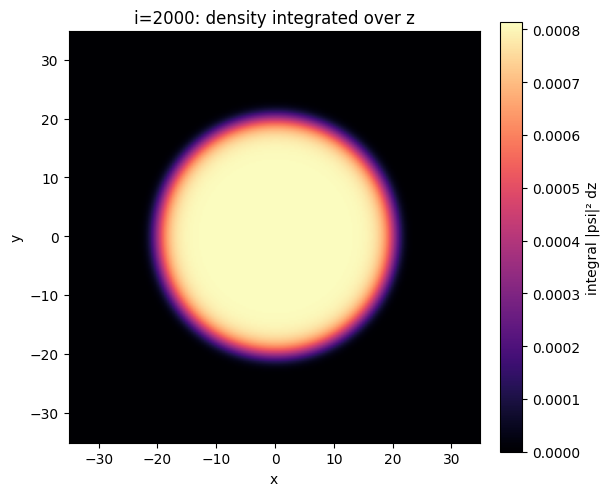

Saving ground_state to Drive...
ground_state: N=1; saved to /content/drive/MyDrive/GPE_simulator/simulation_results/20261010T121244869976Z_N256/ground_state


In [7]:
imag_steps=2000
assert imag_steps>0
metadata['imag_steps']=imag_steps
write_metadata()
print(f"Preparation: {imag_steps} steps, imaginary dt={imag_dt:g}, tau={imag_steps*imag_dt:g}")

x_array,k_array=get_grids(N_grids,cfg.simulation_range)
psi=gaussian(x_array,sigma)
box=box_potential(x_array,cfg.R,cfg.L,cfg.wallthickness,2)
start=time.perf_counter()
with tqdm(total=imag_steps,desc="Imaginary time",unit="step") as bar:
    reported=0
    for i in range(1,imag_steps+1):
        psi=imaginary_step(psi,box,beta,k_array,imag_dt,N_grids,x_array)
        if i%progress_interval==0 or i==imag_steps:
            cp.cuda.get_current_stream().synchronize()
            bar.update(i-reported)
            bar.set_postfix(tau=f"{i*imag_dt:g}")
            reported=i
imag_wall_s=time.perf_counter()-start
print("Preparation complete: in-situ density integrated over z")
monitor(imag_steps,psi,k_array,x_array,show_magnifier_interval=imag_steps)
save_state("ground_state",imag_steps,imag_steps*imag_dt,0.0,imag_wall_s)
stage="prepared"


## 2. Stir for 250 time units

Keep the prepared state, add the configured absorber, and start the drive at t=0.
`ssfmstep_timeV` evaluates the potential at each step's midpoint. The momentum
cutoff is disabled. The requested monitors run only in this stage.

In [8]:
assert stage=="prepared", "Run the preparation cell before starting stirring."
cp.get_default_memory_pool().free_all_blocks()
absorber=absorption_potential(cfg.r_abs,cfg.A_abs,x_array,cfg.simulation_range)
V_static=get_total_static_potential(box,absorber)
del box,absorber
cp.get_default_memory_pool().free_all_blocks()
stage="stirring"
start=time.perf_counter()
with tqdm(total=stir_steps,desc="Stirring",unit="step") as bar:
    reported=0
    for i in range(1,stir_steps+1):
        t=(i-1)*dt
        step_dt=min(dt,stir_duration-t)
        psi=ssfmstep_timeV(psi,V_static,beta,k_array,x_array,step_dt,N_grids,kcut,t)
        observe_stirring(i,psi,min(i*dt,stir_duration))
        if i%progress_interval==0 or i==stir_steps:
            cp.cuda.get_current_stream().synchronize()
            bar.update(i-reported)
            bar.set_postfix(t=f"{min(i*dt,stir_duration):g}")
            reported=i
stir_wall_s=time.perf_counter()-start
save_state("after_stirring",stir_steps,stir_duration,stir_duration,stir_wall_s)
stage="stirred"


Output hidden; open in https://colab.research.google.com to view.

## 3. Free evolution for another 1000 time units

Continue from the stirred state using ordinary `ssfmstep`. The box and absorber
stay on; the time-dependent drive and stirring monitors are off. There is no
normalization or momentum cutoff in this stage.

In [12]:
assert stage=="stirred", "Finish the stirring cell before starting free evolution."
stage="free_evolution"
start=time.perf_counter()
with tqdm(total=free_steps,desc="Free evolution",unit="step") as bar:
    reported=0
    for i in range(1,free_steps+1):
        step_dt=min(dt,free_duration-(i-1)*dt)
        psi=ssfmstep(psi,V_static,beta,k_array,step_dt,N_grids)

        monitor_relaxation(i,psi)
        if i%progress_interval==0 or i==free_steps:
            cp.cuda.get_current_stream().synchronize()
            bar.update(i-reported)
            bar.set_postfix(t=f"{stir_duration+min(i*dt,free_duration):g}")
            reported=i
free_wall_s=time.perf_counter()-start
save_state("final",free_steps,free_duration,stir_duration+free_duration,free_wall_s)
stage="complete"
print(f"Finished: real time={stir_duration+free_duration:g}; results at {DRIVE_RUN}")


AssertionError: Finish the stirring cell before starting free evolution.

In [11]:
def monitor_relaxation(i,psi):
    if i%500!=0:
        return

    t=stir_duration+min(i*dt,free_duration)
    print(f"Relaxation: t={t:g}")
    psi_k=cp.fft.fftn(psi)

    monitor(
        i,psi,k_array,x_array,
        print_scalar_interval=500,
        show_TOF_image_interval=1000,
        show_verticle_TOF_interval=1000,
        show_magnifier_slice_interval=1000,
        show_phase_interval=1000,
        psi_k=psi_k,
    )

    if i%1500==0:
        spectrum=nk_extraction(psi_k,x_array,k_array)
        k=cp.asnumpy(spectrum['k'])
        nk=cp.asnumpy(spectrum['nk'])
        positive=(k>0)&(nk>0)

        fig,ax=plt.subplots(figsize=(6,4),layout="constrained")
        ax.loglog(k[positive],nk[positive])
        ax.set(xlabel="k",ylabel="n(k), shell average",
               title=f"Relaxation: i={i}, t={t:g}")
        plt.show()
        plt.close(fig)